# Niche-type prediction in normal and cancerous liver (prototype level)

CosMx liver, normal and cancer, analysed the same way. Niche labels in both
datasets are spatially defined: in normal liver every cell type occurs in all
six zones, and in cancer the interface label is assigned by location. The
classifier therefore sits on the niche level (`level="niche"`): each cell's
Level-2 attention over the 20 pretrained niche prototypes is mapped to the
annotated labels by a learnable prototype -> label matrix.

The two label sets differ (zonation vs tumour compartments), so the two
classifiers are separate models and their scores are not directly comparable.

## 1. Setup

In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# --- edit these -------------------------------------------------------
FOUNDATION_CKPT = "/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt"
VOCAB_PATH      = "/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json"

LEVEL = "niche"           # "cell" = linear head on z0, for comparison

# continual adaptation before the classifier (self-supervised, train split only)
DO_CONTINUAL  = True
N_CONTINUAL   = 10
LR_CONTINUAL  = 1e-4      # also test 1e-3
RUN_TAG = f"{LEVEL}_cont{N_CONTINUAL}_lr{LR_CONTINUAL:g}" if DO_CONTINUAL else f"{LEVEL}_pretrained"

DATASETS = {
    "normal": {
        "data_root": "/DATA1/Roxana/Hierarchy/Two_levels/fine_tune/Liver_cosmax_normal",
        "h5ad":      "/DATA1/Roxana/Data/Normal_liver_cosmax.h5ad",
        "output":    f"./results/liver_normal_{RUN_TAG}",
    },
    "cancer": {
        "data_root": "/DATA1/Roxana/Hierarchy/Two_levels/fine_tune/Liver_cosmax_cancer",
        "h5ad":      "/DATA1/Roxana/Data/cancer_liver_cosmax.h5ad",
        "output":    f"./results/liver_cancer_{RUN_TAG}",
    },
}
# ----------------------------------------------------------------------

TARGET_KEY  = "y_niche"
SPLIT_COL   = "split"
FOV_COL     = "fov"
SPOT_SIZE   = 0.01
DEVICE      = "cuda:0"
BATCH_SIZE  = 512
NUM_WORKERS = 4
SEED        = 42

device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")
for cfg in DATASETS.values():
    os.makedirs(cfg["output"], exist_ok=True)
print("device:", device, "| run:", RUN_TAG)

device: cuda:0 | run: niche_cont10_lr0.0001


## 2. Building the supervised sections

Each dataset is written as `train.pt` and `test.pt`, split on the `split`
column in `obs`. The files from the earlier run can be reused: the community
partition (`node2comm`, `super_sp`) is the same input the new hierarchy uses.
Set `BUILD_SECTIONS = True` only if they do not exist yet.

In [2]:
from pathlib import Path
import scanpy as sc

from hebi.data.graph import build_spatial_graph
from hebi.data.coarsening import create_metis_partition
from hebi.data.vocabulary import harmonise_adata

BUILD_SECTIONS = False

LABEL_COL_CLASS = "cell_type"
LABEL_COL_NICHE = "niche_type"
K_NEIGHBORS     = 10

if BUILD_SECTIONS:
    for name, cfg in DATASETS.items():
        root = Path(cfg["data_root"])
        (root / "train").mkdir(parents=True, exist_ok=True)
        (root / "test").mkdir(parents=True, exist_ok=True)

        ad_full = sc.read_h5ad(cfg["h5ad"])
        ad_full = harmonise_adata(ad_full, VOCAB_PATH, species="human")
        sc.pp.normalize_total(ad_full, target_sum=1e4)
        sc.pp.log1p(ad_full)

        class_to_id = {l: i for i, l in
                       enumerate(sorted(ad_full.obs[LABEL_COL_CLASS].unique().astype(str)))}
        niche_to_id = {l: i for i, l in
                       enumerate(sorted(ad_full.obs[LABEL_COL_NICHE].unique().astype(str)))}
        with open(root / "label_mappings.json", "w") as f:
            json.dump({"class_mapping": class_to_id, "niche_mapping": niche_to_id},
                      f, indent=4)
        print(f"{name}: {len(class_to_id)} classes, {len(niche_to_id)} niches")

        for split in ad_full.obs[SPLIT_COL].unique().tolist():
            d = ad_full[ad_full.obs[SPLIT_COL] == split].copy()

            X = d.X.toarray() if hasattr(d.X, "toarray") else np.asarray(d.X)
            X = torch.tensor(X, dtype=torch.float32)
            coords = torch.tensor(
                d.obsm["spatial"] if "spatial" in d.obsm else d.obsm["spatial_3d"][:, :2],
                dtype=torch.float32,
            )

            edge_index, edge_attr, _ = build_spatial_graph(coords.numpy(),
                                                           k=K_NEIGHBORS)
            n_clusters = 1024 if d.n_obs >= 1024 else max(1, d.n_obs // 10)
            node2comm, super_sp = create_metis_partition(
                edge_index, X.shape[0], n_clusters, seed=SEED
            )

            torch.save({
                "X": X.half(),
                "coords": coords,
                "edge_index": edge_index,
                "node2comm": node2comm,
                "super_sp": super_sp,
                "gene_ids": torch.tensor(d.var["gene_id"].values, dtype=torch.long),
                "y_class": torch.tensor(
                    [class_to_id[l] for l in d.obs[LABEL_COL_CLASS].astype(str)],
                    dtype=torch.long),
                "y_niche": torch.tensor(
                    [niche_to_id[l] for l in d.obs[LABEL_COL_NICHE].astype(str)],
                    dtype=torch.long),
                "meta": {"species": "Human", "tissue": "Liver", "condition": name,
                         "k_neighbors": K_NEIGHBORS},
            }, root / split / f"{split}.pt")
            print(f"   {split}: {d.n_obs:,} cells")

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Labels

In [3]:
for name, cfg in DATASETS.items():
    with open(os.path.join(cfg["data_root"], "label_mappings.json")) as f:
        mappings = json.load(f)

    key = "class_mapping" if TARGET_KEY == "y_class" else "niche_mapping"
    label_to_id = mappings[key]
    cfg["label_names"] = [
        k for k, _ in sorted(label_to_id.items(), key=lambda kv: kv[1])
    ]
    cfg["n_classes"] = len(cfg["label_names"])

    print(f"{name}: {cfg['n_classes']} classes")
    for i, label in enumerate(cfg["label_names"]):
        print(f"   {i:>2}  {label}")
    print()

normal: 6 classes
    0  Zone_1a/PV
    1  Zone_1b
    2  Zone_2a
    3  Zone_2b
    4  Zone_3a
    5  Zone_3b/CV

cancer: 4 classes
    0  interface
    1  non-malignant
    2  tumor
    3  tumor subtype



## 4. Continual adaptation

Before the classifier, the pretrained model is adapted to each dataset with
the self-supervised pretraining objective (no labels). With
`init="pretrained"` the niche level (pooler, Level 2 and the 20 niche
prototypes) is re-initialised and learned on the target tissue, as in the
continual mode of the unsupervised pipeline. Only the training split is used,
so the test FOVs are never seen before evaluation.

In [4]:
from hebi.inference.adapt import continual_adapt

for name, cfg in DATASETS.items():
    if not DO_CONTINUAL:
        cfg["backbone_ckpt"] = FOUNDATION_CKPT
        continue

    cfg["backbone_ckpt"] = os.path.join(cfg["output"], "hebi_continual.pt")
    if os.path.exists(cfg["backbone_ckpt"]):
        print(f"{name}: using existing {cfg['backbone_ckpt']}")
        continue

    print(f"\n{'=' * 60}\n{name}: continual adaptation\n{'=' * 60}")
    continual_adapt(
        checkpoint_path=FOUNDATION_CKPT,
        data_dir=os.path.join(cfg["data_root"], "train"),
        vocab_path=VOCAB_PATH,
        device=DEVICE,
        lr=LR_CONTINUAL,
        num_epochs=N_CONTINUAL,
        output_checkpoint=cfg["backbone_ckpt"],
        init="pretrained",
    )
    torch.cuda.empty_cache()

normal: using existing ./results/liver_normal_niche_cont10_lr0.0001/hebi_continual.pt
cancer: using existing ./results/liver_cancer_niche_cont10_lr0.0001/hebi_continual.pt


In [6]:
from hebi.training.finetune.loader import load_supervised_slide_dict, build_local_sampler


@torch.no_grad()
def section_outputs(model, pt_path):
    """Per-cell niche attention for a whole split file."""
    slide = load_supervised_slide_dict(pt_path, target_key=TARGET_KEY)
    X   = slide["X"].float().to(device)
    n2c = slide["node2comm"].long().to(device)
    ssp = slide["super_sp"].float().to(device)
    gid = slide["gene_ids"].long().to(device)
    greps = model.section_global_reps(slide, device, batch_size=BATCH_SIZE,
                                      num_workers=NUM_WORKERS)
    sampler = build_local_sampler(slide, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS)
    A = np.full((X.shape[0], model.k2), np.nan, dtype=np.float32)
    for eb, idx, bs in sampler:
        idx = idx.to(device); seed = idx[:bs]
        _, attn = model(X[idx], eb[:2].to(device),
                        (eb[2].to(device), eb[3].to(device)),
                        n2c[seed], ssp, gid, device, bs,
                        global_reps=greps, return_attention=True)
        A[seed.cpu().numpy()] = attn.float().cpu().numpy()
    return A, slide["coords"].cpu().numpy(), slide[TARGET_KEY].cpu().numpy()

In [7]:
#check1
# Step 1 diagnostic: is a prototype's meaning consistent inside each FOV but
# different across FOVs?  No training; labels are only used to measure.
# Needs cell A (section_outputs) to have been run.
import scanpy as sc
from sklearn.metrics import f1_score
from hebi.training.finetune.finetuner import HebiClassifier
from hebi.training.finetune.loader import get_slide_list

MIN_MASS, MIN_NEFF = 20.0, 30.0       # enough attention mass for a (FOV, prototype) pair


def split_attention(name, split):
    """Attention [n, K2], labels [n], FOV id [n] for one split, in .pt order."""
    cfg = DATASETS[name]
    if "_obs" not in cfg:
        cfg["_obs"] = sc.read_h5ad(cfg["h5ad"], backed="r").obs[[SPLIT_COL, FOV_COL]].copy()
    obs = cfg["_obs"]
    fov = obs.loc[obs[SPLIT_COL].astype(str) == split, FOV_COL].astype(str).to_numpy()

    ck = torch.load(cfg["backbone_ckpt"], map_location="cpu")
    k2 = ck["pooler_lvl2"]["l2_prototypes"].shape[0]; del ck
    m = HebiClassifier(n_classes=cfg["n_classes"], level="niche",
                       num_prototypes_lvl2=k2).to(device)
    m.load_pretrained_weights(cfg["backbone_ckpt"], device, freeze_backbone=True)
    m.eval()
    A, _, y = section_outputs(m, get_slide_list(cfg["data_root"], split=split)[0])
    del m; torch.cuda.empty_cache()

    assert len(fov) == len(y), "AnnData split and .pt cell counts differ"
    ok = ~np.isnan(A).any(1)
    return A[ok], y[ok], fov[ok]


def soft_counts(A, y, fov, K):
    """n[f, k, y] = sum of attention to prototype k of cells in FOV f with label y."""
    fovs = np.unique(fov)
    n = np.zeros((len(fovs), A.shape[1], K))
    for a, f in enumerate(fovs):
        sel = fov == f
        for c in range(K):
            n[a, :, c] = A[sel & (y == c)].sum(0)
    neff = np.array([(A[fov == f].sum(0) ** 2) / ((A[fov == f] ** 2).sum(0) + 1e-12)
                     for f in fovs])
    return fovs, n, neff


def entropy(p):
    p = p / p.sum(-1, keepdims=True)
    return -(p * np.log(p + 1e-12)).sum(-1)


def conditional_entropies(n):
    """H(Y|K) and H(Y|K,FOV); pair weights from raw counts, Jeffreys (+0.5) only
    inside the conditional distributions."""
    total = n.sum()
    nk = n.sum(0)                                         # [K2, K]
    w_k = nk.sum(1) / total
    H_k = (w_k * entropy(nk + 0.5)).sum()
    w_fk = n.sum(2) / total                               # [F, K2]
    H_fk = (w_fk * entropy(n + 0.5)).sum()
    return H_k, H_fk


def hard_predict(A, fov, global_map, fov_maps=None):
    proto = A.argmax(1)
    pred = global_map[proto].copy()
    if fov_maps is not None:
        for f, fmap in fov_maps.items():
            sel = fov == f
            pred[sel] = fmap[proto[sel]]
    return pred


for name, cfg in DATASETS.items():
    K, names = cfg["n_classes"], cfg["label_names"]
    A_tr, y_tr, f_tr = split_attention(name, "train")
    A_te, y_te, f_te = split_attention(name, "test")

    print(f"\n{'=' * 64}\n{name}\n{'=' * 64}")

    # 1. entropies: does knowing the FOV remove the ambiguity of a prototype?
    for tag, (A, y, f) in {"train": (A_tr, y_tr, f_tr), "test": (A_te, y_te, f_te)}.items():
        _, n, _ = soft_counts(A, y, f, K)
        H_k, H_fk = conditional_entropies(n)
        dH = H_k - H_fk
        print(f"  [{tag}] H(Y|K) = {H_k:.3f}   H(Y|K,FOV) = {H_fk:.3f}   "
              f"dH = {dH:.3f}   dH/H(Y|K) = {dH / (H_k + 1e-12):.1%}   "
              f"(H(Y) = {entropy(np.bincount(y, minlength=K) + 0.5):.3f})")

    # 2. global mapping (learned on train) vs per-FOV oracle mapping (test labels)
    fovs_tr, n_tr, _ = soft_counts(A_tr, y_tr, f_tr, K)
    global_map = n_tr.sum(0).argmax(1)                    # prototype -> label

    fovs_te, n_te, neff_te = soft_counts(A_te, y_te, f_te, K)
    fov_maps = {}
    for a, f in enumerate(fovs_te):
        fmap = global_map.copy()
        mass = n_te[a].sum(1)
        ok = (mass >= MIN_MASS) & (neff_te[a] >= MIN_NEFF)
        fmap[ok] = n_te[a][ok].argmax(1)
        fov_maps[f] = fmap

    pred_g = hard_predict(A_te, f_te, global_map)
    pred_o = hard_predict(A_te, f_te, global_map, fov_maps)
    for tag, pred in [("global map", pred_g), ("per-FOV oracle map", pred_o)]:
        f1 = f1_score(y_te, pred, average="macro", labels=np.arange(K), zero_division=0)
        line = f"  test {tag:<20} macro-F1 {f1:.3f}   acc {np.mean(pred == y_te):.3f}"
        if name == "normal":                              # labels sorted PV -> CV
            line += f"   zone MAE {np.mean(np.abs(pred - y_te)):.3f}"
        print(line)

    # 3. per prototype: global meaning vs how often FOVs disagree with it
    rows = []
    P_g = n_tr.sum(0) / (n_tr.sum(0).sum(1, keepdims=True) + 1e-12)
    mass_tr = n_tr.sum(2)
    neff_tr = soft_counts(A_tr, y_tr, f_tr, K)[2]
    for k in range(A_tr.shape[1]):
        ok = (mass_tr[:, k] >= MIN_MASS) & (neff_tr[:, k] >= MIN_NEFF)
        if ok.sum() == 0:
            continue
        top_f = n_tr[ok, k].argmax(1)
        pur_f = n_tr[ok, k].max(1) / n_tr[ok, k].sum(1)
        rows.append({"prototype": f"P{k}",
                     "global label": names[global_map[k]],
                     "global purity": round(P_g[k].max(), 2),
                     "FOVs": int(ok.sum()),
                     "mean FOV purity": round(pur_f.mean(), 2),
                     "FOVs disagreeing": f"{np.mean(top_f != global_map[k]):.0%}"})
    print("\n  per prototype (train, FOVs with enough mass):")
    print(pd.DataFrame(rows).to_string(index=False))

📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001/hebi_continual.pt
❄️ Backbone frozen
📁 Found 1 slides for split 'train'
📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001/hebi_continual.pt
❄️ Backbone frozen
📁 Found 1 slides for split 'test'

normal
  [train] H(Y|K) = 1.438   H(Y|K,FOV) = 1.180   dH = 0.258   dH/H(Y|K) = 17.9%   (H(Y) = 1.475)
  [test] H(Y|K) = 1.306   H(Y|K,FOV) = 1.052   dH = 0.254   dH/H(Y|K) = 19.4%   (H(Y) = 1.359)
  test global map           macro-F1 0.110   acc 0.420   zone MAE 0.785
  test per-FOV oracle map   macro-F1 0.397   acc 0.561   zone MAE 0.579

  per prototype (train, FOVs with enough mass):
prototype global label  global purity  FOVs  mean FOV purity FOVs disagreeing
       P1      Zone_2b           0.41    47             0.47              47%
       P2      Zone_2a           0.36   144             0.47              57%
       P4      Zone_2b           0.45   170             0.53              55%
       P5      Zone

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001_trans/hebi_continual.pt
❄️ Backbone frozen
normal fov 172 (test, 1,309 cells): prototypes [1, 3, 5, 7, 8, 9, 11, 12, 13, 15, 19]


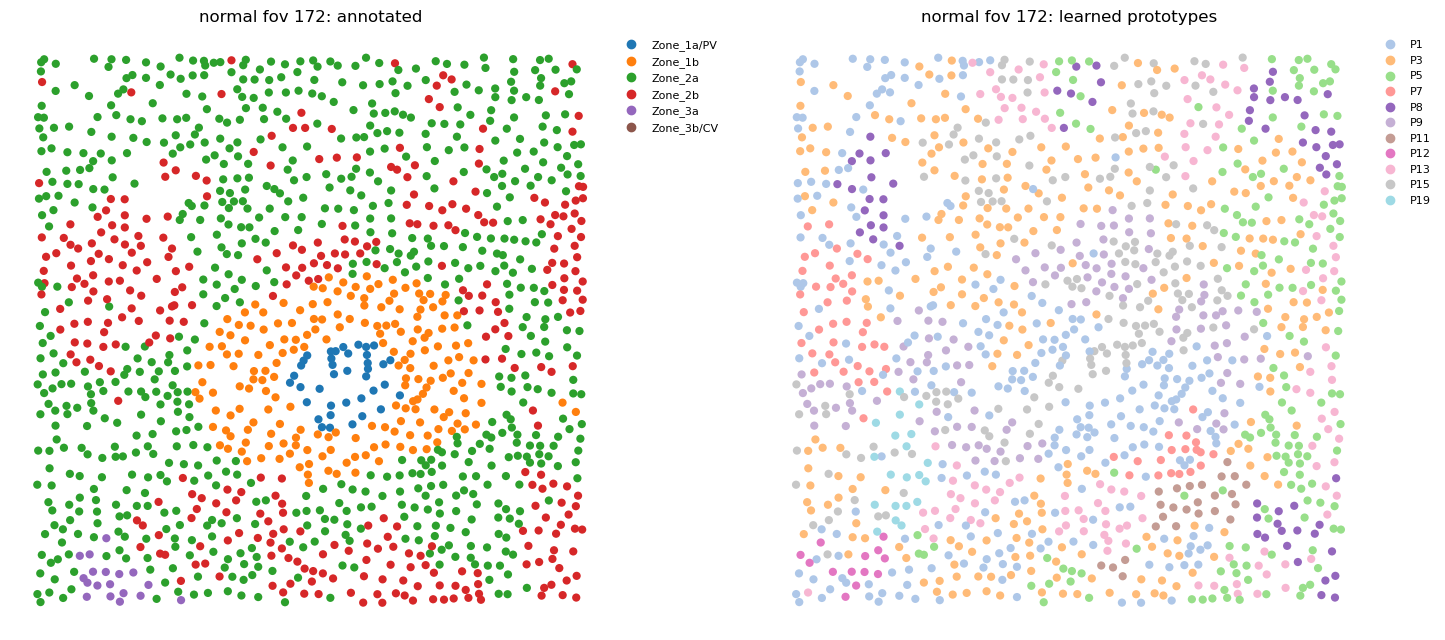

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: ./results/liver_cancer_niche_cont10_lr0.0001_trans/hebi_continual.pt
❄️ Backbone frozen
cancer fov 176 (test, 1,220 cells): prototypes [0, 2, 5, 8, 10, 12, 14, 15, 19]


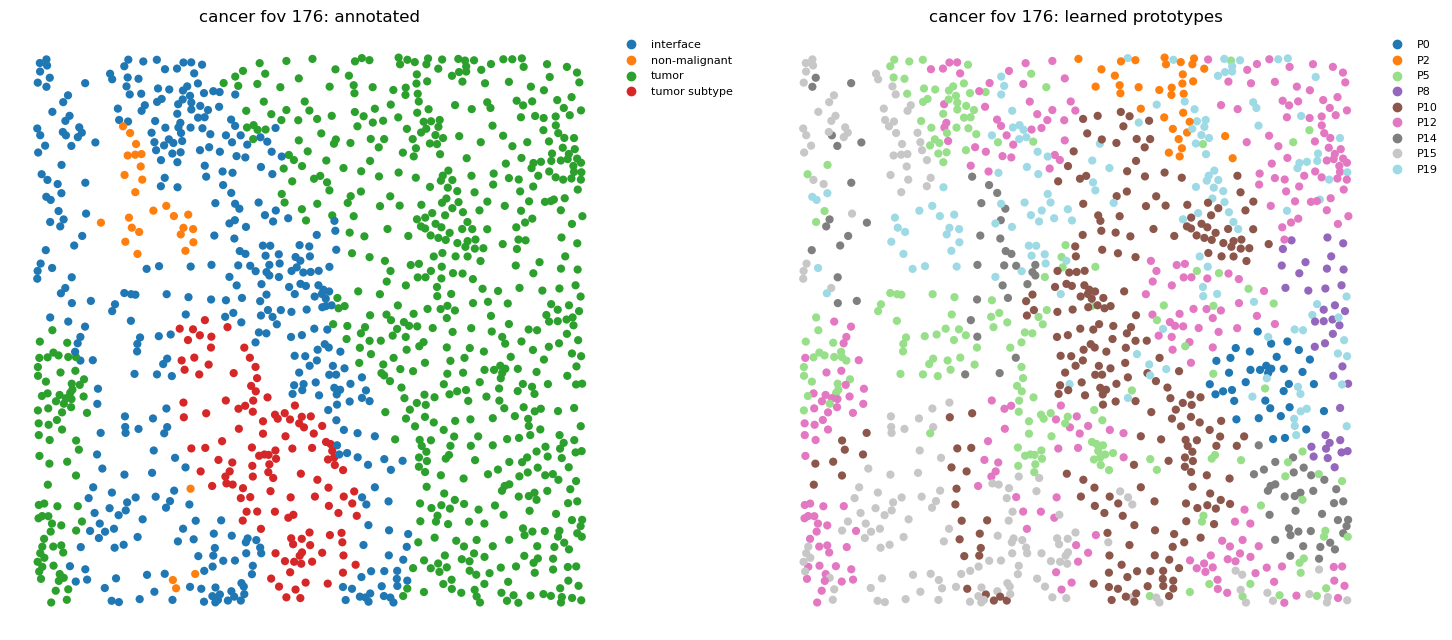

In [5]:
import scanpy as sc
from hebi.training.finetune.finetuner import HebiClassifier
from hebi.training.finetune.loader import (
    get_slide_list, load_supervised_slide_dict, build_local_sampler,
)

FOVS = {"normal": 172, "cancer": 176}
LABEL_COLORS = plt.get_cmap("tab10")
PROTO_COLORS = plt.get_cmap("tab20")


def fov_cells(name, fov):
    """Which split holds this FOV, and a boolean mask over that split's cells
    in .pt order (the .pt was written from adata[split] in obs order)."""
    cfg = DATASETS[name]
    if "_obs" not in cfg:
        cfg["_obs"] = sc.read_h5ad(cfg["h5ad"], backed="r").obs[[SPLIT_COL, FOV_COL]].copy()
    obs = cfg["_obs"]
    hit = obs[obs[FOV_COL].astype(str) == str(fov)]
    if hit.empty:
        raise ValueError(f"{name}: fov {fov} not found")
    splits = hit[SPLIT_COL].astype(str).unique()
    assert len(splits) == 1, f"fov {fov} spans splits {splits}"
    split = splits[0]
    sub = obs[obs[SPLIT_COL].astype(str) == split]
    return split, (sub[FOV_COL].astype(str) == str(fov)).to_numpy()


@torch.no_grad()
def section_outputs(model, pt_path):
    """Per-cell niche attention for a whole split file."""
    slide = load_supervised_slide_dict(pt_path, target_key=TARGET_KEY)
    X   = slide["X"].float().to(device)
    n2c = slide["node2comm"].long().to(device)
    ssp = slide["super_sp"].float().to(device)
    gid = slide["gene_ids"].long().to(device)
    greps = model.section_global_reps(slide, device, batch_size=BATCH_SIZE,
                                      num_workers=NUM_WORKERS)
    sampler = build_local_sampler(slide, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS)
    A = np.full((X.shape[0], model.k2), np.nan, dtype=np.float32)
    for eb, idx, bs in sampler:
        idx = idx.to(device); seed = idx[:bs]
        _, attn = model(X[idx], eb[:2].to(device),
                        (eb[2].to(device), eb[3].to(device)),
                        n2c[seed], ssp, gid, device, bs,
                        global_reps=greps, return_attention=True)
        A[seed.cpu().numpy()] = attn.float().cpu().numpy()
    return A, slide["coords"].cpu().numpy(), slide[TARGET_KEY].cpu().numpy()


def _scatter(ax, xy, colors, title, handles):
    ax.scatter(xy[:, 0], xy[:, 1], s=35, c=colors, linewidths=0)
    ax.set_title(title)
    ax.set_aspect("equal"); ax.axis("off")
    ax.legend(handles=handles, frameon=False, fontsize=8,
              loc="upper left", bbox_to_anchor=(1.0, 1.0))


def _label_handles(names):
    return [plt.Line2D([], [], marker="o", ls="", color=LABEL_COLORS(i % 10), label=l)
            for i, l in enumerate(names)]


def plot_fov_prototypes(name):
    cfg, fov = DATASETS[name], FOVS[name]
    split, mask = fov_cells(name, fov)
    pt = get_slide_list(cfg["data_root"], split=split)[0]

    ck = torch.load(cfg["backbone_ckpt"], map_location="cpu")
    k2 = ck["pooler_lvl2"]["l2_prototypes"].shape[0]; del ck
    m = HebiClassifier(n_classes=cfg["n_classes"], level="niche",
                       num_prototypes_lvl2=k2).to(device)
    m.load_pretrained_weights(cfg["backbone_ckpt"], device, freeze_backbone=True)
    m.eval()
    A, xy, y = section_outputs(m, pt)
    del m; torch.cuda.empty_cache()
    assert len(mask) == len(y), "AnnData split and .pt cell counts differ"

    A, xy, y = A[mask], xy[mask], y[mask]
    proto = A.argmax(1)
    used = sorted(set(proto.tolist()))
    print(f"{name} fov {fov} ({split}, {mask.sum():,} cells): prototypes {used}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    _scatter(axes[0], xy, [LABEL_COLORS(int(k) % 10) for k in y],
             f"{name} fov {fov}: annotated", _label_handles(cfg["label_names"]))
    _scatter(axes[1], xy, [PROTO_COLORS(int(k) % 20) for k in proto],
             f"{name} fov {fov}: learned prototypes",
             [plt.Line2D([], [], marker="o", ls="", color=PROTO_COLORS(k % 20),
                         label=f"P{k}") for k in used])
    plt.tight_layout()
    plt.savefig(os.path.join(cfg["output"], f"fov{fov}_prototypes.svg"), bbox_inches="tight")
    plt.show()


for name in DATASETS:
    plot_fov_prototypes(name)

## 5. Training

Linear probe (backbone frozen, only the prototype -> label matrix trains),
then fine-tuning at a much lower backbone learning rate. Whole-section
community representations are used in training and evaluation alike, and the
pooler keeps its soft assignment in both phases. Selection on macro-F1.

In [6]:
from hebi.training.finetune.train_classifier import train_classifier

for name, cfg in DATASETS.items():
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    cfg["history"] = train_classifier(
        foundation_ckpt=cfg["backbone_ckpt"],
        data_root=cfg["data_root"],
        output_dir=cfg["output"],
        level=LEVEL,
        target_key=TARGET_KEY,

        n_epochs_linear=5,
        lr_linear=1e-4,

        do_finetune=False,
        n_epochs_finetune=5,
        lr_finetune=1e-3,

        batch_size=BATCH_SIZE,
        device=DEVICE,
        num_workers=NUM_WORKERS,
        seed=SEED,
    )


normal
Task: y_niche (6 classes) | level: niche | niche prototypes: 20
📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001_trans/hebi_continual.pt
❄️ Backbone frozen
📁 Found 1 slides for split 'train'
📁 Found 1 slides for split 'test'

Phase 1: linear probing (5 epochs)


P1 1/5: 100%|███████████████| 1/1 [00:23<00:00, 23.19s/it, acc=0.366, loss=1.77]


  P1 ep 1 | train acc=0.3664  macroF1=0.1403  microF1=0.3664
           | test  acc=0.4115  macroF1=0.1536  microF1=0.4115
           | saved (macroF1 0.1536)


P1 2/5: 100%|███████████████| 1/1 [00:22<00:00, 22.99s/it, acc=0.384, loss=1.73]


  P1 ep 2 | train acc=0.3843  macroF1=0.1259  microF1=0.3843
           | test  acc=0.3985  macroF1=0.1458  microF1=0.3985


P1 3/5: 100%|████████████████| 1/1 [00:23<00:00, 23.34s/it, acc=0.381, loss=1.7]


... (11 outputs left out)

P1 4/5: 100%|███████████████| 1/1 [00:31<00:00, 31.93s/it, acc=0.704, loss=1.17]


  P1 ep 4 | train acc=0.7038  macroF1=0.2401  microF1=0.7038
           | test  acc=0.7092  macroF1=0.3107  microF1=0.7092


P1 5/5: 100%|███████████████| 1/1 [00:31<00:00, 31.89s/it, acc=0.704, loss=1.12]


  P1 ep 5 | train acc=0.7038  macroF1=0.2401  microF1=0.7038
           | test  acc=0.7108  macroF1=0.3214  microF1=0.7108
           | saved (macroF1 0.3214)

Skipping phase 2.

Best macro-F1: 0.3214
Outputs in ./results/liver_cancer_niche_cont10_lr0.0001_trans


In [9]:
from collections import Counter
from sklearn.metrics import f1_score, classification_report

# Hard prototype -> label evaluation of the linear probe.
#   soft : p(label | cell) = attn(cell) @ softmax(W)            (what was trained)
#   hard : cell -> argmax prototype -> argmax label of that row  (pure mapping)

TAG = "probe"

for name, cfg in DATASETS.items():
    ckpt = os.path.join(cfg["output"], f"best_{TAG}_model.pt")
    model = load_trained_model(ckpt, cfg["n_classes"], cfg["backbone_ckpt"],
                               device, level="niche")
    M = model.prototype_label_map().detach().cpu().numpy()          # [K2, K]
    proto_to_label = M.argmax(1)                                     # hard map

    with open(os.path.join(cfg["output"], f"prototype_label_map_{TAG}.json")) as f:
        pm = json.load(f)
    estimable = np.array([p["estimable"] for p in pm["prototypes"]])

    pt = get_slide_list(cfg["data_root"], split="test")[0]
    slide = load_supervised_slide_dict(pt, target_key=TARGET_KEY)
    X   = slide["X"].float().to(device)
    n2c = slide["node2comm"].long().to(device)
    ssp = slide["super_sp"].float().to(device)
    gid = slide["gene_ids"].long().to(device)
    y   = slide[TARGET_KEY].cpu().numpy()

    soft  = np.full(X.shape[0], -1)
    proto = np.full(X.shape[0], -1)
    with torch.no_grad():
        greps = model.section_global_reps(slide, device, batch_size=BATCH_SIZE,
                                          num_workers=NUM_WORKERS)
        sampler = build_local_sampler(slide, batch_size=BATCH_SIZE, shuffle=False,
                                      num_workers=NUM_WORKERS)
        for eb, idx, bs in sampler:
            idx = idx.to(device); seed = idx[:bs]
            log_p, attn = model(X[idx], eb[:2].to(device),
                                (eb[2].to(device), eb[3].to(device)),
                                n2c[seed], ssp, gid, device, bs,
                                global_reps=greps, return_attention=True)
            s = seed.cpu().numpy()
            soft[s]  = log_p.argmax(1).cpu().numpy()
            proto[s] = attn.argmax(1).cpu().numpy()
    del model
    torch.cuda.empty_cache()

    ok = proto >= 0
    y, soft, proto = y[ok], soft[ok], proto[ok]
    hard = proto_to_label[proto]
    names = cfg["label_names"]
    K = cfg["n_classes"]

    print(f"\n{'=' * 60}\n{name} ({TAG}) — {len(y):,} test cells\n{'=' * 60}")
    for tag, pred in [("soft", soft), ("hard", hard)]:
        print(f"  {tag}: acc {np.mean(pred == y):.4f}   macro-F1 "
              f"{f1_score(y, pred, average='macro', labels=np.arange(K), zero_division=0):.4f}")

    in_unest = ~estimable[proto]
    print(f"  test cells whose prototype is not estimable: {in_unest.mean():.2%}")

    # the mapping, with how many test cells each prototype holds
    counts = Counter(proto.tolist())
    rows = []
    for k in range(len(proto_to_label)):
        if counts.get(k, 0) == 0 and not estimable[k]:
            continue
        rows.append({"prototype": f"P{k}",
                     "label": names[proto_to_label[k]],
                     "p(label)": round(float(M[k, proto_to_label[k]]), 3),
                     "estimable": bool(estimable[k]),
                     "test_cells": counts.get(k, 0)})
    table = pd.DataFrame(rows).sort_values(["label", "test_cells"],
                                           ascending=[True, False])
    print("\n  prototype -> label")
    print(table.to_string(index=False))

    labels_reached = sorted(set(proto_to_label[list(counts)]))
    missing = [names[k] for k in range(K) if k not in labels_reached]
    print(f"\n  labels with no prototype: {missing if missing else 'none'}")

    print("\n  hard mapping, per class:")
    print(classification_report(y, hard, labels=np.arange(K), target_names=names,
                                zero_division=0))

📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001_trans/hebi_continual.pt
🔥 Backbone trainable
📁 Found 1 slides for split 'test'

normal (probe) — 29,458 test cells
  soft: acc 0.4054   macro-F1 0.1516
  hard: acc 0.4294   macro-F1 0.1816
  test cells whose prototype is not estimable: 3.87%

  prototype -> label
prototype      label  p(label)  estimable  test_cells
      P16 Zone_1a/PV     0.167      False         485
      P14 Zone_1a/PV     0.167      False         354
      P10 Zone_1a/PV     0.167      False         102
      P11 Zone_1a/PV     0.167      False          78
      P18 Zone_1a/PV     0.167      False          69
      P17 Zone_1a/PV     0.167      False          51
       P7    Zone_2a     0.178       True        1615
       P8    Zone_2a     0.179       True        1388
      P19    Zone_2a     0.180       True         981
      P12    Zone_2a     0.178       True         292
       P3    Zone_2b     0.179       True        5480
      P15    Zone_2b 

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: ./results/liver_normal_niche_cont10_lr0.0001_trans/hebi_continual.pt
🔥 Backbone trainable
normal fov 172 (test): mapped-label accuracy 0.284


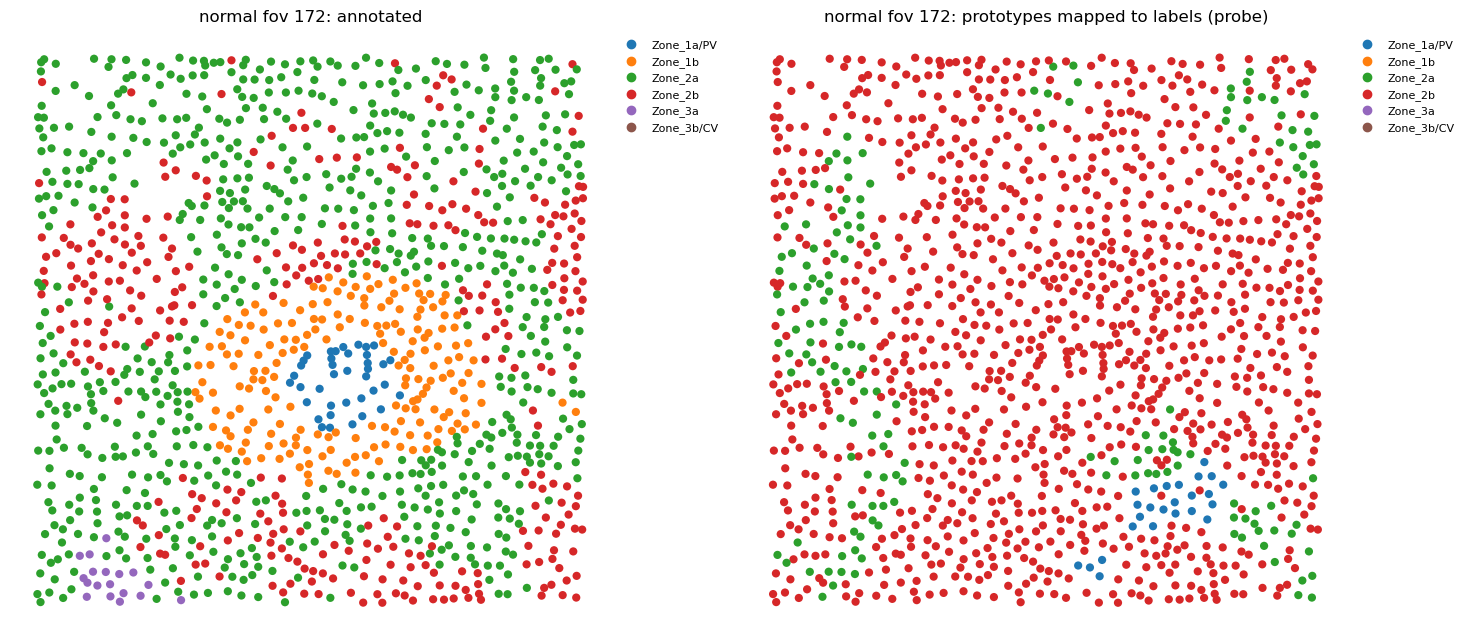

📁 Found 1 slides for split 'test'
📥 Loading checkpoint: ./results/liver_cancer_niche_cont10_lr0.0001_trans/hebi_continual.pt
🔥 Backbone trainable
cancer fov 176 (test): mapped-label accuracy 0.536


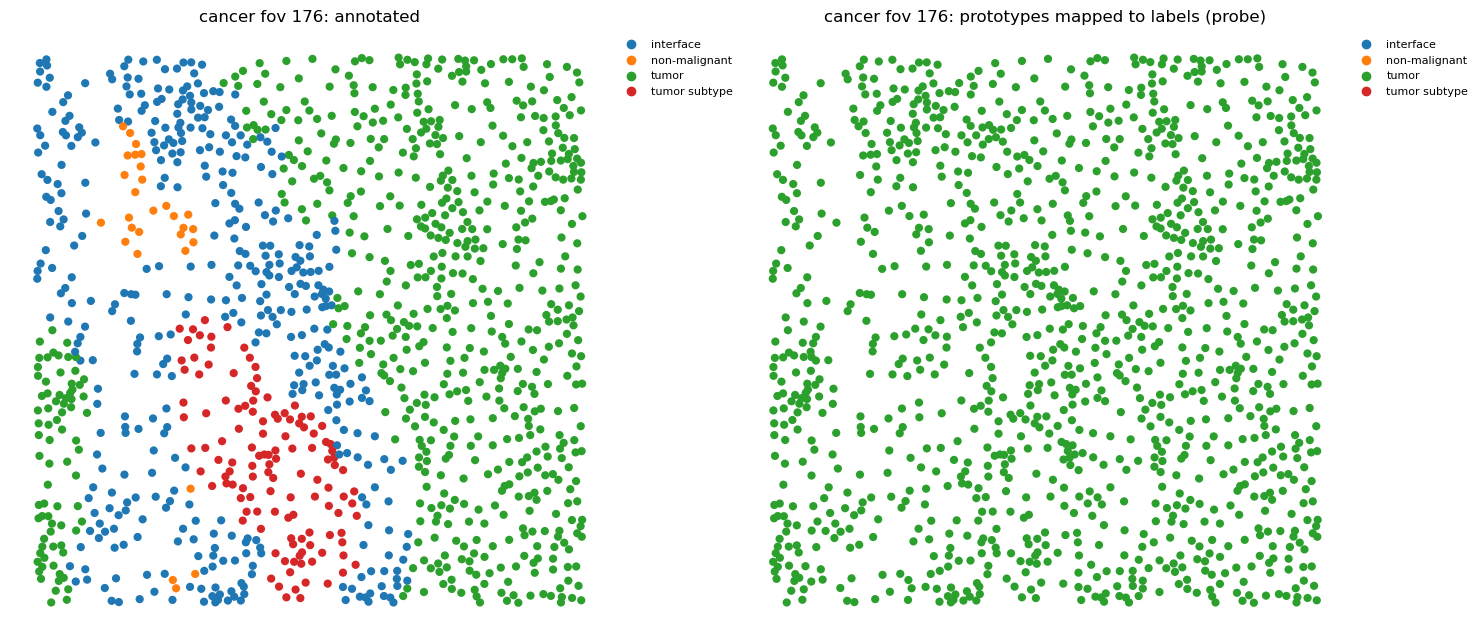

In [10]:
def plot_fov_mapped(name, tag="probe"):
    cfg, fov = DATASETS[name], FOVS[name]
    split, mask = fov_cells(name, fov)
    pt = get_slide_list(cfg["data_root"], split=split)[0]

    m = load_trained_model(os.path.join(cfg["output"], f"best_{tag}_model.pt"),
                           cfg["n_classes"], cfg["backbone_ckpt"], device, level="niche")
    proto_to_label = m.prototype_label_map().detach().cpu().numpy().argmax(1)
    A, xy, y = section_outputs(m, pt)
    del m; torch.cuda.empty_cache()
    assert len(mask) == len(y), "AnnData split and .pt cell counts differ"

    A, xy, y = A[mask], xy[mask], y[mask]
    mapped = proto_to_label[A.argmax(1)]          # cell -> prototype -> label
    print(f"{name} fov {fov} ({split}): mapped-label accuracy {np.mean(mapped == y):.3f}")

    names = cfg["label_names"]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    _scatter(axes[0], xy, [LABEL_COLORS(int(k) % 10) for k in y],
             f"{name} fov {fov}: annotated", _label_handles(names))
    _scatter(axes[1], xy, [LABEL_COLORS(int(k) % 10) for k in mapped],
             f"{name} fov {fov}: prototypes mapped to labels ({tag})",
             _label_handles(names))
    plt.tight_layout()
    plt.savefig(os.path.join(cfg["output"], f"fov{fov}_mapped_{tag}.svg"), bbox_inches="tight")
    plt.show()


for name in DATASETS:
    plot_fov_mapped(name)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, (name, cfg) in zip(axes, DATASETS.items()):
    h = cfg["history"]
    x = np.arange(1, len(h) + 1)
    ax.plot(x, [e["train"]["macro_f1"] for e in h], "o-", label="train")
    ax.plot(x, [e["test"]["macro_f1"] for e in h], "o-", label="test")

    phases = [e["phase"] for e in h]
    if 2 in phases:
        ax.axvline(phases.index(2) + 0.5, color="grey", ls="--", lw=1)

    best = max(h, key=lambda e: e["test"]["macro_f1"])["test"]
    ax.set_title(f"{name}: {cfg['n_classes']} classes, "
                 f"best macro-F1 {best['macro_f1']:.3f}")
    ax.set_xlabel("epoch")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("macro-F1")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Predicting whole sections

Predictions are written into an array in the section's own cell order. At the
niche level the whole-section community representations are computed first,
as in evaluation.

In [8]:
from hebi.training.finetune.finetuner import HebiClassifier
from hebi.training.finetune.loader import (
    get_slide_list, load_supervised_slide_dict, build_local_sampler,
)


def load_trained_model(checkpoint_path, n_classes, foundation_ckpt, device,
                       level="cell"):
    ckpt = torch.load(foundation_ckpt, map_location="cpu")
    k2 = ckpt["pooler_lvl2"]["l2_prototypes"].shape[0]
    del ckpt

    model = HebiClassifier(n_classes=n_classes, level=level,
                           num_prototypes_lvl2=k2).to(device)
    model.load_pretrained_weights(foundation_ckpt, device, freeze_backbone=False)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()
    return model


@torch.no_grad()
def predict_section(model, pt_path, target_key, device,
                    batch_size=512, num_workers=4):
    """Predict every cell in one section, in the section's own cell order.

    Returns (pred, true), both length n_cells. Cells that never appear as a
    seed node keep -1 and are reported.
    """
    slide   = load_supervised_slide_dict(pt_path, target_key=target_key)
    sampler = build_local_sampler(slide, batch_size=batch_size,
                                  shuffle=False, num_workers=num_workers)

    X         = slide["X"].float().to(device)
    node2comm = slide["node2comm"].long().to(device)
    super_sp  = slide["super_sp"].float().to(device)
    gene_ids  = slide["gene_ids"].long().to(device)
    true      = slide[target_key].long().cpu().numpy()

    global_reps = None
    if model.level == "niche":
        global_reps = model.section_global_reps(
            slide, device, batch_size=batch_size, num_workers=num_workers)

    pred = np.full(X.shape[0], -1, dtype=np.int64)

    for edge_block, node_idx_b, bs in sampler:
        node_idx_b = node_idx_b.to(device)
        seed = node_idx_b[:bs]
        logits = model(
            x_subgraph_raw=X[node_idx_b],
            edge_index_subgraph=edge_block[:2].to(device),
            edge_attr_b=(edge_block[2].to(device), edge_block[3].to(device)),
            node2comm_batch=node2comm[seed],
            super_sp_global=super_sp,
            gene_ids=gene_ids,
            device=device,
            bs=bs,
            global_reps=global_reps,
        )
        pred[seed.cpu().numpy()] = logits.argmax(dim=1).cpu().numpy()

    unseen = int((pred < 0).sum())
    if unseen:
        print(f"  {unseen} cells never appeared as a seed node")
    return pred, true

In [ ]:
for name, cfg in DATASETS.items():
    ckpt = os.path.join(cfg["output"], "best_finetuned_model.pt")
    if not os.path.exists(ckpt):
        ckpt = os.path.join(cfg["output"], "best_probe_model.pt")
    cfg["checkpoint"] = ckpt

    model = load_trained_model(ckpt, cfg["n_classes"], cfg["backbone_ckpt"],
                               device, level=LEVEL)
    cfg["per_section"] = {}

    print(f"\n{name} ({os.path.basename(ckpt)})")
    for pt_path in get_slide_list(cfg["data_root"], split="test"):
        section = os.path.basename(pt_path).replace(".pt", "")
        pred, true = predict_section(model, pt_path, TARGET_KEY, device,
                                     batch_size=BATCH_SIZE,
                                     num_workers=NUM_WORKERS)
        cfg["per_section"][section] = {"pred": pred, "true": true}
        acc = float((pred == true)[pred >= 0].mean())
        print(f"  {section:<30} {len(pred):>7,} cells   acc {acc:.4f}")

    del model
    torch.cuda.empty_cache()

## 7. Confusion matrices

Computed on integer class ids; names are used only for the tick labels.
Rows are normalised, so the diagonal is per-class recall. In normal liver,
confusion between adjacent zones is the expected failure of a gradient;
confusion between `Zone_1a/PV` and `Zone_3b/CV`, the two ends, would not be.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

for name, cfg in DATASETS.items():
    K = cfg["n_classes"]
    y_true = np.concatenate([d["true"][d["pred"] >= 0]
                             for d in cfg["per_section"].values()])
    y_pred = np.concatenate([d["pred"][d["pred"] >= 0]
                             for d in cfg["per_section"].values()])

    cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
    cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(1.5 + 0.7 * K, 1.2 + 0.6 * K))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, shrink=0.7, label="fraction of true class")

    ax.set_xticks(np.arange(K)); ax.set_yticks(np.arange(K))
    ax.set_xticklabels(cfg["label_names"], rotation=90, fontsize=8)
    ax.set_yticklabels(cfg["label_names"], fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{name} liver")

    for i in range(K):
        for j in range(K):
            if cm_norm[i, j] > 0.01:
                ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                        fontsize=8,
                        color="white" if cm_norm[i, j] > 0.5 else "black")

    plt.tight_layout()
    plt.savefig(os.path.join(cfg["output"], "confusion_matrix.svg"))
    plt.show()

    print(classification_report(y_true, y_pred, labels=np.arange(K),
                                target_names=cfg["label_names"],
                                zero_division=0))

## 8. Predictions in space

The test set is a single `.pt`; the AnnData is subset the same way, by the
`split` column, which puts the two in the same order. The assertion stops if
the counts disagree. Set `FOV_TO_PLOT` to look at one field of view.

In [ ]:
import scanpy as sc

DATASET_TO_PLOT = "normal"
FOV_TO_PLOT     = None        # None plots every test cell at once

cfg = DATASETS[DATASET_TO_PLOT]
section = list(cfg["per_section"])[0]        # "test"

adata = sc.read_h5ad(cfg["h5ad"])
sub = adata[adata.obs[SPLIT_COL].astype(str) == section].copy()

pred = cfg["per_section"][section]["pred"]
true = cfg["per_section"][section]["true"]
assert sub.n_obs == len(pred), (
    f"{sub.n_obs} cells in the AnnData but {len(pred)} in the section file. "
    "The .pt fixes the cell order, so these must match."
)

names = cfg["label_names"]
sub.obs["annotated"] = pd.Categorical([names[i] for i in true], categories=names)
sub.obs["predicted"] = pd.Categorical(
    [names[i] if i >= 0 else "unassigned" for i in pred],
    categories=names + ["unassigned"],
)

if FOV_TO_PLOT is not None:
    sub = sub[sub.obs[FOV_COL].astype(str) == str(FOV_TO_PLOT)].copy()

label = f"{DATASET_TO_PLOT}" + (f" fov {FOV_TO_PLOT}" if FOV_TO_PLOT else "")
sc.pl.spatial(sub, color=["annotated", "predicted"], spot_size=SPOT_SIZE,
              title=[f"annotated: {label}", f"predicted: {label}"],
              wspace=0.3, show=True)

mismatch = (sub.obs["annotated"].astype(str) != sub.obs["predicted"].astype(str))
print(f"{mismatch.sum():,} of {sub.n_obs:,} cells misclassified "
      f"({mismatch.mean():.1%})")

## 9. Prototype -> label map

The learned matrix: for each of the 20 niche prototypes, its distribution over
the annotated labels. Prototypes that received less than 0.1% of the training
attention mass are marked not estimable (their row barely trained) and shown
greyed out. The probe map labels the original pretrained prototypes; the
fine-tuned map labels them after supervised adaptation.

In [ ]:
def load_map(output_dir, tag):
    path = os.path.join(output_dir, f"prototype_label_map_{tag}.json")
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)


def plot_map(pm, title, save_path=None):
    labels = pm["labels"]
    protos = pm["prototypes"]
    M = np.array([[p["label_distribution"][l] for l in labels] for p in protos])
    est = np.array([p["estimable"] for p in protos])
    mass = np.array([p["attention_mass_frac"] for p in protos])

    fig, ax = plt.subplots(figsize=(1.5 + 0.6 * len(labels), 1 + 0.32 * len(protos)))
    ax.imshow(np.where(est[:, None], M, np.nan), cmap="Blues", vmin=0, vmax=1,
              aspect="auto")
    ax.imshow(np.where(~est[:, None], 1.0, np.nan), cmap="Greys", vmin=0, vmax=4,
              aspect="auto")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(protos)))
    ax.set_yticklabels([f"P{p['prototype']}  ({m:.1%})" for p, m in zip(protos, mass)],
                       fontsize=8)
    ax.set_xlabel("annotated niche"); ax.set_ylabel("prototype (attention mass)")
    ax.set_title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


for name, cfg in DATASETS.items():
    for tag in ("probe", "finetuned"):
        pm = load_map(cfg["output"], tag)
        if pm is None:
            continue
        plot_map(pm, f"{name}: prototype -> label ({tag})",
                 os.path.join(cfg["output"], f"prototype_label_map_{tag}.svg"))
        table = pd.DataFrame([{
            "prototype": p["prototype"], "label": p["label"],
            "mass": round(p["attention_mass_frac"], 4),
            "n_hard": p["n_hard_assigned"],
            "entropy": round(p["row_entropy"], 3),
        } for p in pm["prototypes"]])
        print(f"\n{name} ({tag})")
        print(table.to_string(index=False))